In [ ]:
# SkinInsight
# Skincare Product Rating Prediction
# Using Linear Regression

print("Welcome to SkinInsight")
print("Project: Skincare Product Rating Prediction")
print("Algorithm: Linear Regression")

Welcome to SkinInsight
Project: Skincare Product Rating Prediction
Algorithm: Linear Regression


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
df = pd.read_csv('/content/product_info.csv')

print("Dataset loaded successfully!")

FileNotFoundError: [Errno 2] No such file or directory: '/content/product_info.csv'

In [ ]:
df.head()

,product_id,product_name,brand_id,brand_name,loves_count,rating,reviews,size,variation_type,variation_value,...,online_only,out_of_stock,sephora_exclusive,highlights,primary_category,secondary_category,tertiary_category,child_count,child_max_price,child_min_price
0,P473671,Fragrance Discovery Set,6342,19-69,6320,3.6364,11.0,NaN,NaN,NaN,...,1,0,0,"['Unisex/ Genderless Scent', 'Warm &Spicy Scen...",Fragrance,Value & Gift Sets,Perfume Gift Sets,0,NaN,NaN
1,P473668,La Habana Eau de Parfum,6342,19-69,3827,4.1538,13.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,85.0,30.0
2,P473662,Rainbow Bar Eau de Parfum,6342,19-69,3253,4.2500,16.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0
3,P473660,Kasbah Eau de Parfum,6342,19-69,3018,4.4762,21.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0
4,P473658,Purple Haze Eau de Parfum,6342,19-69,2691,3.2308,13.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0


In [ ]:
print("Dataset shape:", df.shape)

Dataset shape: (8494, 27)


In [ ]:
print(df.columns.tolist())

['product_id', 'product_name', 'brand_id', 'brand_name', 'loves_count', 'rating', 'reviews', 'size', 'variation_type', 'variation_value', 'variation_desc', 'ingredients', 'price_usd', 'value_price_usd', 'sale_price_usd', 'limited_edition', 'new', 'online_only', 'out_of_stock', 'sephora_exclusive', 'highlights', 'primary_category', 'secondary_category', 'tertiary_category', 'child_count', 'child_max_price', 'child_min_price']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8494 entries, 0 to 8493
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   product_id          8494 non-null   object 
 1   product_name        8494 non-null   object 
 2   brand_id            8494 non-null   int64  
 3   brand_name          8494 non-null   object 
 4   loves_count         8494 non-null   int64  
 5   rating              8216 non-null   float64
 6   reviews             8216 non-null   float64
 7   size                6863 non-null   object 
 8   variation_type      7050 non-null   object 
 9   variation_value     6896 non-null   object 
 10  variation_desc      1250 non-null   object 
 11  ingredients         7549 non-null   object 
 12  price_usd           8494 non-null   float64
 13  value_price_usd     451 non-null    float64
 14  sale_price_usd      270 non-null    float64
 15  limited_edition     8494 non-null   int64  
 16  new   

In [ ]:
print(df.isnull().sum())

product_id               0
product_name             0
brand_id                 0
brand_name               0
loves_count              0
rating                 278
reviews                278
size                  1631
variation_type        1444
variation_value       1598
variation_desc        7244
ingredients            945
price_usd                0
value_price_usd       8043
sale_price_usd        8224
limited_edition          0
new                      0
online_only              0
out_of_stock             0
sephora_exclusive        0
highlights            2207
primary_category         0
secondary_category       8
tertiary_category      990
child_count              0
child_max_price       5740
child_min_price       5740
dtype: int64


In [ ]:
print(df['primary_category'].value_counts())

primary_category
Skincare           2420
Makeup             2369
Hair               1464
Fragrance          1432
Bath & Body         405
Mini Size           288
Men                  60
Tools & Brushes      52
Gifts                 4
Name: count, dtype: int64


In [ ]:
print(df['rating'].describe())

count    8216.000000
mean        4.194513
std         0.516694
min         1.000000
25%         3.981725
50%         4.289350
75%         4.530525
max         5.000000
Name: rating, dtype: float64


In [ ]:
skin_df = df[
    df['primary_category'].str.contains(
        'skincare', case=False, na=False
    )
].copy()

print("Skincare products:", len(skin_df))

skin_df.head()

Skincare products: 2420


,product_id,product_name,brand_id,brand_name,loves_count,rating,reviews,size,variation_type,variation_value,...,online_only,out_of_stock,sephora_exclusive,highlights,primary_category,secondary_category,tertiary_category,child_count,child_max_price,child_min_price
89,P439055,GENIUS Sleeping Collagen Moisturizer,6018,Algenist,33910,4.5413,1321.0,2 oz/ 60 mL,Size,2 oz/ 60 mL,...,0,0,1,"['Vegan', 'Good for: Loss of firmness', 'Colla...",Skincare,Moisturizers,Moisturizers,0,NaN,NaN
90,P421277,GENIUS Liquid Collagen Serum,6018,Algenist,67870,4.0259,1159.0,1 oz / 30 mL,Size,1 oz / 30 mL,...,0,0,1,"['Vegan', 'Good for: Loss of firmness', 'Colla...",Skincare,Treatments,Face Serums,1,25.0,25.0
91,P467602,Triple Algae Eye Renewal Balm Eye Cream,6018,Algenist,17890,4.5306,1142.0,NaN,NaN,NaN,...,0,0,1,NaN,Skincare,Eye Care,Eye Creams & Treatments,0,NaN,NaN
92,P432045,GENIUS Liquid Collagen Lip Treatment,6018,Algenist,44448,3.8721,649.0,.5 oz / 15 mL,Size,.5 oz / 15 mL,...,0,0,1,"['Vegan', 'Good for: Loss of firmness', 'Plump...",Skincare,Lip Balms & Treatments,NaN,0,NaN,NaN
93,P311143,SUBLIME DEFENSE Ultra Lightweight UV Defense F...,6018,Algenist,27278,4.4134,508.0,1 oz,Size,1 oz,...,0,0,0,"['Vegan', 'Hypoallergenic', 'UV Protection', '...",Skincare,Sunscreen,Face Sunscreen,0,NaN,NaN


In [ ]:
skin_df = skin_df.dropna(subset=['rating'])

print("Rows after removing missing ratings:", len(skin_df))

Rows after removing missing ratings: 2351


In [ ]:
print("Duplicate product IDs:", skin_df['product_id'].duplicated().sum())

Duplicate product IDs: 0


In [ ]:
skin_df = skin_df.drop_duplicates(subset=['product_id'])

In [ ]:
print(skin_df['rating'].min())
print(skin_df['rating'].max())

1.0
5.0


In [ ]:
numeric_features = [
    'price_usd',
    'loves_count',
    'reviews',
    'child_count',
    'online_only',
    'sephora_exclusive',
    'limited_edition',
    'new'
]

categorical_features = [
    'secondary_category',
    'tertiary_category'
]

# Keep only columns available in the dataset
numeric_features = [
    col for col in numeric_features if col in skin_df.columns
]

categorical_features = [
    col for col in categorical_features if col in skin_df.columns
]

features = numeric_features + categorical_features

X = skin_df[features]
y = skin_df['rating']

print("Input features:", features)
print("Target: rating")

Input features: ['price_usd', 'loves_count', 'reviews', 'child_count', 'online_only', 'sephora_exclusive', 'limited_edition', 'new', 'secondary_category', 'tertiary_category']
Target: rating


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1880
Testing records: 471


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Data preprocessing is ready!")

Data preprocessing is ready!


In [ ]:
from sklearn.linear_model import LinearRegression

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)

print("SkinInsight model trained successfully!")

SkinInsight model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Rating': y_test.values,
    'Predicted Rating': y_pred
})

print(results.head(10))

   Actual Rating  Predicted Rating
0         4.3980          4.328860
1         4.2727          4.031486
2         4.6414          4.093425
3         4.4260          4.296354
4         3.9583          4.107459
5         3.5000          4.150533
6         4.7300          4.240764
7         4.6723          4.434580
8         4.7813          4.252677
9         4.3182          4.193699


In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.3477763320646789
RMSE: 0.4639724035400803
R2 Score: 0.07555449008017745


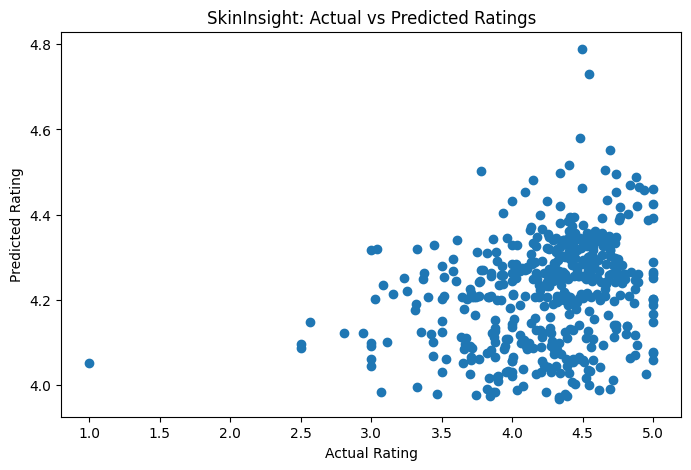

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("SkinInsight: Actual vs Predicted Ratings")

plt.show()

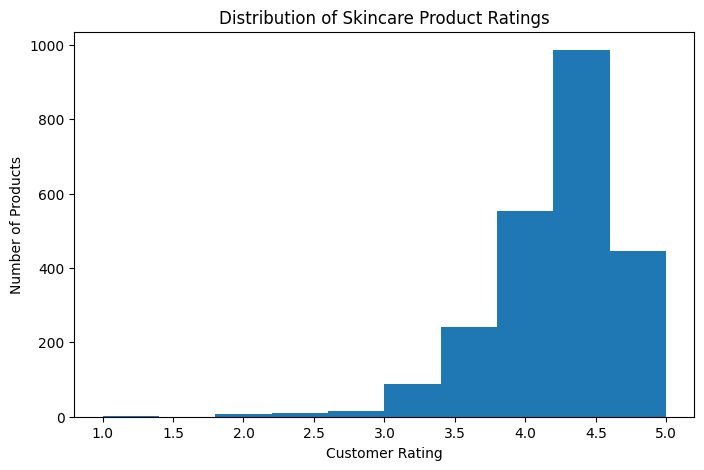

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(skin_df['rating'], bins=10)

plt.xlabel("Customer Rating")
plt.ylabel("Number of Products")
plt.title("Distribution of Skincare Product Ratings")

plt.show()

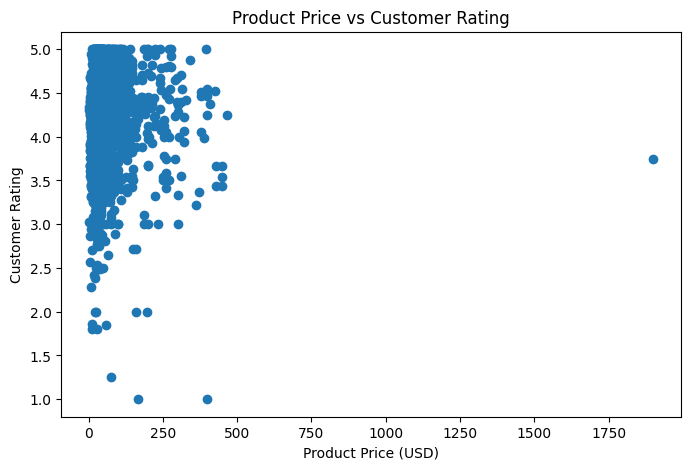

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    skin_df['price_usd'],
    skin_df['rating']
)

plt.xlabel("Product Price (USD)")
plt.ylabel("Customer Rating")
plt.title("Product Price vs Customer Rating")

plt.show()

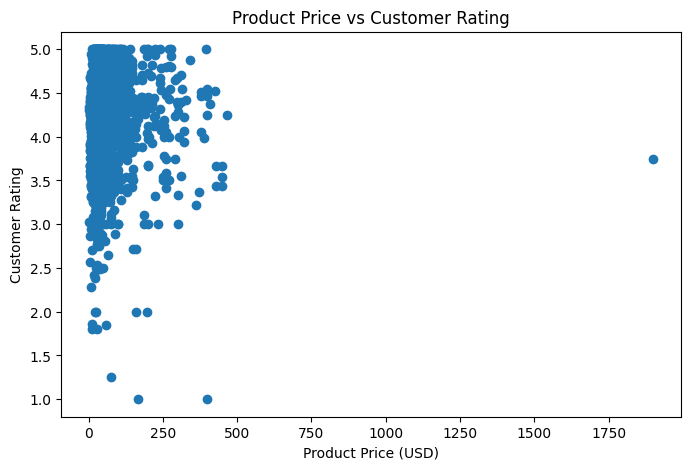

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    skin_df['price_usd'],
    skin_df['rating']
)

plt.xlabel("Product Price (USD)")
plt.ylabel("Customer Rating")
plt.title("Product Price vs Customer Rating")

plt.show()

In [ ]:
sample_product = X_test.iloc[[0]]

predicted_rating = model.predict(sample_product)

print("Product information:")
print(sample_product)

print("Predicted rating:",
      round(predicted_rating[0], 2), "/ 5")

Product information:
      price_usd  loves_count  reviews  child_count  online_only  \
7676        5.0        48131    294.0            0            1   

      sephora_exclusive  limited_edition  new secondary_category  \
7676                  0                0    0         Treatments   

     tertiary_category  
7676       Face Serums  
Predicted rating: 4.33 / 5


In [ ]:
import joblib

joblib.dump(model, 'SkinInsight_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download('SkinInsight_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
results.to_csv('SkinInsight_predictions.csv', index=False)

files.download('SkinInsight_predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>